In [ ]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from hmda.data import load_hmda, approved_vs_denied

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [ ]:
# VA/NC 2024-2025, actions 1-5 (approved, denied, withdrawn, incomplete).
# First run builds data/processed/va_nc_2024_2025.parquet from the raw FFIEC files
# (downloading them if needed); after that it loads in seconds. See README "Get the data".
df = load_hmda()

print(df.shape)
df.groupby(["activity_year", "state_code"]).size()

In [ ]:
# main task: approved vs denied only (adds 0/1 `denied` column)
main = approved_vs_denied(df)

print(df["outcome"].value_counts())
print("\nmain task rows:", len(main))
print("overall denial rate:", round(main["denied"].mean(), 3))

In [ ]:
# denial rate by loan purpose
purpose_map = {"1": "home purchase", "2": "home improvement", "31": "refinance",
               "32": "cash-out refi", "4": "other", "5": "not applicable"}
main["purpose"] = main["loan_purpose"].map(purpose_map)

(main.groupby("purpose")["denied"]
     .agg(denial_rate="mean", n="size")
     .sort_values("denial_rate", ascending=False))

,denial_rate,n
purpose,,
other,0.390725,160343
home improvement,0.355606,146474
not applicable,0.321212,165
cash-out refi,0.316984,181460
refinance,0.204515,176300
home purchase,0.124661,590239


,state_code,activity_year,denial_rate,n
0,NC,2024,0.239994,355442
1,NC,2025,0.228188,384933
2,VA,2024,0.221183,246041
3,VA,2025,0.202502,268565


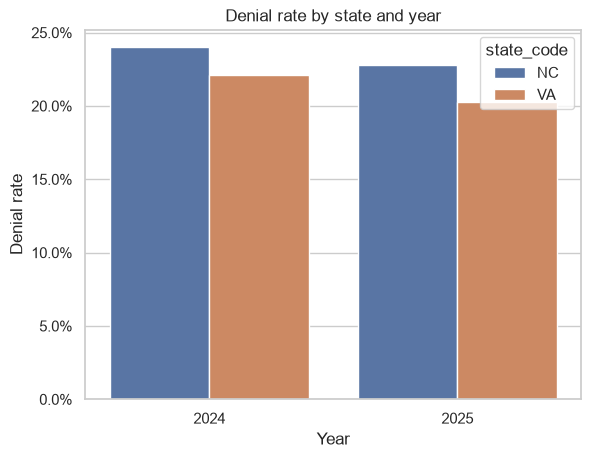

In [ ]:
# Cell 4: denial rates by state and year
rates = (main.groupby(["state_code", "activity_year"])["denied"]
             .agg(denial_rate="mean", n="size")
             .reset_index())
display(rates)

ax = sns.barplot(data=rates, x="activity_year", y="denial_rate", hue="state_code")
ax.set(title="Denial rate by state and year", xlabel="Year", ylabel="Denial rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.show()

In [ ]:
# analysis scope
USE_CORE = True

core_mask = (
    (main["loan_purpose"] == "1") &      # home purchase
    (main["lien_status"] == "1") &       # first lien
    (main["occupancy_type"] == "1")      # owner-occupied
)
eda = main[core_mask].copy() if USE_CORE else main.copy()

print("rows:", len(eda))
print("denial rate:", round(eda["denied"].mean(), 3))

rows: 497472
denial rate: 0.124


In [ ]:
# Cell 6: missing values
def missing_share(d):
    return (d.isna() | d.isin(["Exempt", "NA"])).mean() * 100

by_year = pd.DataFrame({y: missing_share(g) for y, g in eda.groupby("activity_year")}).round(1)
by_year = by_year[by_year.max(axis=1) > 0].sort_values(by_year.columns[-1], ascending=False)
print("% missing by year (columns with any missing):")
display(by_year.head(30))

by_outcome = pd.DataFrame({
    "approved": missing_share(eda[eda["denied"] == 0]),
    "denied":   missing_share(eda[eda["denied"] == 1]),
}).round(1)
by_outcome["gap"] = by_outcome["denied"] - by_outcome["approved"]
print("% missing, approved vs denied (biggest gaps):")
display(by_outcome.reindex(by_outcome["gap"].abs().sort_values(ascending=False).index).head(15))

% missing by year (columns with any missing):


,2024,2025
co_applicant_race_4,100.0,100.0
applicant_race_5,100.0,100.0
co_applicant_race_5,100.0,100.0
applicant_ethnicity_5,100.0,100.0
co_applicant_ethnicity_3,100.0,100.0
co_applicant_ethnicity_5,100.0,100.0
applicant_ethnicity_4,100.0,100.0
co_applicant_ethnicity_4,100.0,100.0
multifamily_affordable_units,100.0,100.0
applicant_ethnicity_3,99.9,99.9


% missing, approved vs denied (biggest gaps):


,approved,denied,gap
interest_rate,0.9,100.0,99.1
rate_spread,2.2,100.0,97.8
origination_charges,6.5,100.0,93.5
total_loan_costs,6.6,100.0,93.4
discount_points,49.8,100.0,50.2
combined_loan_to_value_ratio,6.4,44.5,38.1
lender_credits,68.5,100.0,31.5
denial_reason_2,100.0,74.4,-25.6
co_applicant_age_above_62,55.0,63.3,8.3
denial_reason_3,100.0,94.5,-5.5
